## 지난주 개념 복습!
아래 마크다운을 풀고, 지난주 예습과제를 통해 공부한 Vision Transformer의 특징과 다른 모델들과의 차이점을 간략히 설명해주세요.

ViT는 이미지를 텍스트 문장처럼 다루어 Sequence 형태로 변환해 처리한다. 이의 핵심 아이디어는 이미지를 작은 patch의 집합으로 나누고, 각 패치를 하나의 토큰으로 처리한다는 것이다. 이후 패치 토큰들 사이의 관계를 attention으로 학습힌다. 이러한 구조 덕분에 ViT는 CNN과 달리 이미지 전체 영역의 전역 정보를 한 번에 고려할 수 있다.

## 파이토치로 구현한 Vision Transformer
이번 복습과제에서는 카사바 잎 질병 데이터셋으로 vision transformer를 학습시키겠습니다.
- 첨부된 드라이브에서 필요한 파일들을 다운받을 수 있습니다.

In [4]:
!pip install --force-reinstall torch torchvision torch-xla -f https://storage.googleapis.com/tpu-pytorch/wheels/tpuv2/index.html

Looking in links: https://storage.googleapis.com/tpu-pytorch/wheels/tpuv2/index.html
  Using cached torch_xla-2.9.0-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (18 kB)
  Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached pyyaml-6.0.3-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (2.4 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached charset_normalizer-3.5.2-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (46 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 539.2/539.2 MB 18.7 MB/s  0:00:15
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.2/519.2 MB

### 데이터 불러오기

In [128]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [62]:
#.zip 파일 unzip
!unzip -q /content/drive/MyDrive/EURON/Week9/train_images.zip -d /content/drive/MyDrive/EURON/Week9/train_images

In [18]:
#본인 드라이브의 경로에 맞게 수정해주세요!
!unzip /content/drive/MyDrive/EURON/Week9/jx_vit_base_p16_224-80ecf9dd.pth.zip -d /content/drive/MyDrive/EURON/Week9/jx_vit_base_p16_224-80ecf9dd.pth

Archive:  /content/drive/MyDrive/EURON/Week9/jx_vit_base_p16_224-80ecf9dd.pth.zip
  inflating: /content/drive/MyDrive/EURON/Week9/jx_vit_base_p16_224-80ecf9dd.pth/jx_vit_base_p16_224-80ecf9dd.pth  


In [159]:
#파일 경로
DATA_PATH = "/content/drive/MyDrive/EURON/Week9"
TRAIN_PATH = "/content/drive/MyDrive/EURON/Week9/train_images"
TEST_PATH = "/content/drive/MyDrive/EURON/Week9/test.jpg"
MODEL_PATH = "/content/drive/MyDrive/EURON/Week9/jx_vit_base_p16_224-80ecf9dd.pth/jx_vit_base_p16_224-80ecf9dd.pth"

### 라이브러리

In [160]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("ggplot")

import torch
import torch.nn as nn
import torchvision.transforms as transforms

'''
import torch_xla
import torch_xla.core.xla_model as xm
import torch_xla.distributed.xla_multiprocessing as xmp
import torch_xla.distributed.parallel_loader as pl
'''

import timm

import gc
import os
import time
import random
from datetime import datetime

from PIL import Image
from tqdm.notebook import tqdm
from sklearn import model_selection, metrics

In [161]:
os.environ["XLA_USE_BF16"] = "1"
os.environ["XLA_TENSOR_ALLOCATOR_MAXSIZE"] = "100000000"

In [162]:
def seed_everything(seed):
    """
    Seeds basic parameters for reproductibility of results

    Arguments:
        seed {int} -- Number of the seed
    """
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(1001)

### 파라미터

In [163]:
IMG_SIZE = 224
BATCH_SIZE = 16
LR = 2e-05
GAMMA = 0.7
N_EPOCHS = 1  #모델 학습을 위해서는 더 많은 에포크가 필요하지만, 파일 크기가 큰 관계로 이번 과제에서는 전 과정을 한 번만 수행하겠습니다.

In [164]:
# pandas로 csv 파일을 읽은 뒤, 첫 5행을 출력하세요.
df = pd.read_csv(os.path.join(DATA_PATH, "train.csv"))
df.head()

,image_id,label
0,1000015157.jpg,0
1,1000201771.jpg,3
2,100042118.jpg,1
3,1000723321.jpg,1
4,1000812911.jpg,3


In [165]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21397 entries, 0 to 21396
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   image_id  21397 non-null  object
 1   label     21397 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 334.5+ KB


<Axes: xlabel='label'>

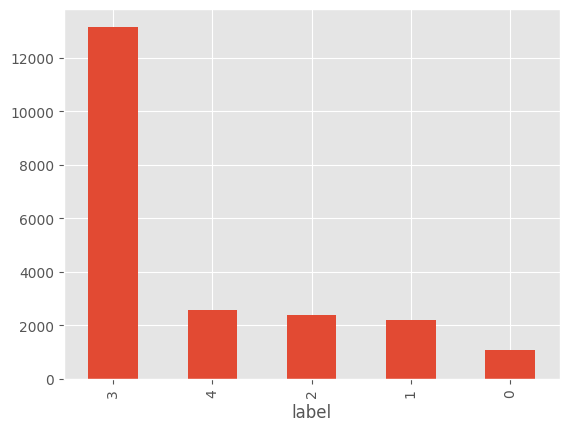

In [166]:
df.label.value_counts().plot(kind="bar")

In [167]:
train_df, valid_df = model_selection.train_test_split(
    df, test_size=0.1, random_state=42, stratify=df.label.values
)

In [168]:
class CassavaDataset(torch.utils.data.Dataset):

    def __init__(self, df, data_path=DATA_PATH, mode="train", transforms=None):
        super().__init__()
        self.df_data = df.values
        self.data_path = data_path
        self.transforms = transforms
        self.mode = mode
        self.data_dir = "train_images" if mode == "train" else "test_images"

    def __len__(self):
        return len(self.df_data)

    def __getitem__(self, index):
        img_name, label = self.df_data[index]
        img_path = os.path.join(self.data_path, self.data_dir, img_name)
        img = Image.open(img_path).convert("RGB")

        if self.transforms is not None:
            image = self.transforms(img)

        return image, label

In [169]:
#데이터 증강
transforms_train = transforms.Compose(
    [
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(p=0.3),
        transforms.RandomResizedCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
    ]
)

transforms_valid = transforms.Compose(
    [
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
    ]
)

In [170]:
#사용 가능한 ViT 모델 목록
##우리는 이중 vit_base_patch16_224를 사용합니다!
print("Available Vision Transformer Models: ")
timm.list_models("vit*")

Available Vision Transformer Models: 


['vit_5b_patch16_sapiens2',
 'vit_7b_patch16_dinov3',
 'vit_base_mci_224',
 'vit_base_patch8_224',
 'vit_base_patch14_dinov2',
 'vit_base_patch14_reg1_tipsv2',
 'vit_base_patch14_reg4_dinov2',
 'vit_base_patch16_18x2_224',
 'vit_base_patch16_224',
 'vit_base_patch16_224_miil',
 'vit_base_patch16_384',
 'vit_base_patch16_clip_224',
 'vit_base_patch16_clip_384',
 'vit_base_patch16_clip_quickgelu_224',
 'vit_base_patch16_dinov3',
 'vit_base_patch16_dinov3_qkvb',
 'vit_base_patch16_gap_224',
 'vit_base_patch16_lingbot',
 'vit_base_patch16_plus_240',
 'vit_base_patch16_plus_clip_240',
 'vit_base_patch16_reg4_gap_256',
 'vit_base_patch16_rope_224',
 'vit_base_patch16_rope_ape_224',
 'vit_base_patch16_rope_mixed_224',
 'vit_base_patch16_rope_mixed_ape_224',
 'vit_base_patch16_rope_reg1_gap_256',
 'vit_base_patch16_rpn_224',
 'vit_base_patch16_sapiens2',
 'vit_base_patch16_siglip_224',
 'vit_base_patch16_siglip_256',
 'vit_base_patch16_siglip_384',
 'vit_base_patch16_siglip_512',
 'vit_base_pa

### 모델 설계
- 클래스 ViTBase16의 각 줄을 설명하는 주석을 달아주세요. (최소 15개)

In [171]:
# 이 셀 안의 코드에 대해서 주석을 달아주세요.
class ViTBase16(nn.Module):
    def __init__(self, n_classes, pretrained=False):

        super(ViTBase16, self).__init__()

        self.model = timm.create_model("vit_base_patch16_224", pretrained=False)
        if pretrained:
            self.model.load_state_dict(torch.load(MODEL_PATH))
            # pretrained가 True인 경우 저장된 가중치 파일(.pth)을 로드하여 모델에 전달

        self.model.head = nn.Linear(self.model.head.in_features, n_classes)

    def forward(self, x):
        x = self.model(x)
        return x

    def train_one_epoch(self, train_loader, criterion, optimizer, device):
        epoch_loss = 0.0
        epoch_accuracy = 0.0
        # 한 에포크 동안의 누적 Loss와 Accuracy를 저장할 수 있는 변수 초기화

        self.model.train()
        for i, (data, target) in enumerate(train_loader):
          # 학습 데이터 로더에서 배치 단위로 이미지 데이터와 정답 라벨을 추출하여 반복
            if device.type == "cuda":
                data, target = data.cuda(), target.cuda()
            elif device.type == "xla":
                data = data.to(device, dtype=torch.float32)
                target = target.to(device, dtype=torch.int64)

            optimizer.zero_grad() # 기울기 초기화
            output = self.forward(data) # 순전파 연산을으로 모델 예측값의 계산
            loss = criterion(output, target) # Loss 계산
            loss.backward() # 역전파
            accuracy = (output.argmax(dim=1) == target).float().mean()
            # 예측값 중 가장 높은 삾을 카진 클래스 인덱스를 찾아 정답과 비교한 후 배치 평균 정확도 계산

            # 배치별 손실값과 정확도를 누적
            epoch_loss += loss
            epoch_accuracy += accuracy

            if device.type == "xla": # TPU 장치 사용하는 경우 PyTorch-XLA의 가중치 업데이트 함수 호출
                xm.optimizer_step(optimizer)

                if i % 20 == 0:
                    xm.master_print(f"\tBATCH {i+1}/{len(train_loader)} - LOSS: {loss}")

            else: # GPU/CPU 환경인 경우 표준 PyTorch 옵티마이저 가중치 업데이트 수행
                optimizer.step()

        return epoch_loss / len(train_loader), epoch_accuracy / len(train_loader)
        # 한 에포크의 평균 손실값과 평균 정확도 반환

    def validate_one_epoch(self, valid_loader, criterion, device):
        valid_loss = 0.0
        valid_accuracy = 0.0
        # 검증 과정의 누적 Loss와 Accuracy를 저장할 변수 초기화

        self.model.eval()
        # 모델을 평가 모드로 전환(Dropuout 비활성화 등)

        for data, target in valid_loader:
            if device.type == "cuda":
                data, target = data.cuda(), target.cuda()
            elif device.type == "xla":
                data = data.to(device, dtype=torch.float32)
                target = target.to(device, dtype=torch.int64)

            with torch.no_grad():
                output = self.model(data)
                loss = criterion(output, target)
                accuracy = (output.argmax(dim=1) == target).float().mean()

                valid_loss += loss
                valid_accuracy += accuracy

        return valid_loss / len(valid_loader), valid_accuracy / len(valid_loader)
        # 검증 데이터셋 전체의 평균 소실 및 평균 정확도 반환

In [172]:
def fit_gpu(model, epochs, device, criterion, optimizer, train_loader, valid_loader=None):
    valid_loss_min = np.inf
    train_losses, valid_losses = [], []
    train_accs, valid_accs = [], []

    for epoch in range(1, epochs + 1):
        gc.collect()
        print(f"{'='*50}")
        print(f"EPOCH {epoch} - TRAINING...")

        train_loss, train_acc = model.train_one_epoch(train_loader, criterion, optimizer, device)
        print(f"\n\t[TRAIN] EPOCH {epoch} - LOSS: {train_loss:.4f}, ACCURACY: {train_acc:.4f}\n")

        train_losses.append(train_loss)
        train_accs.append(train_acc)
        gc.collect()

        if valid_loader is not None:
            print(f"EPOCH {epoch} - VALIDATING...")
            valid_loss, valid_acc = model.validate_one_epoch(valid_loader, criterion, device)
            print(f"\t[VALID] LOSS: {valid_loss:.4f}, ACCURACY: {valid_acc:.4f}\n")

            valid_losses.append(valid_loss)
            valid_accs.append(valid_acc)
            gc.collect()

            if valid_loss <= valid_loss_min and epoch != 1:
                print(f"Validation loss decreased ({valid_loss_min:.4f} --> {valid_loss:.4f}). Saving model...")
            valid_loss_min = valid_loss

    return {
        "train_loss": train_losses,
        "valid_losses": valid_losses,
        "train_acc": train_accs,
        "valid_acc": valid_accs,
    }

In [173]:
model = ViTBase16(n_classes=5, pretrained=True)

In [174]:
def _run():
    train_dataset = CassavaDataset(train_df, transforms=transforms_train)
    valid_dataset = CassavaDataset(valid_df, transforms=transforms_valid)

    train_loader = torch.utils.data.DataLoader(
        dataset=train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=True,
        num_workers=2,
    )

    valid_loader = torch.utils.data.DataLoader(
        dataset=valid_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        drop_last=True,
        num_workers=2,
    )

    criterion = nn.CrossEntropyLoss()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    print(f"INITIALIZING TRAINING ON {device}")
    start_time = datetime.now()
    print(f"Start Time: {start_time}")

    logs = fit_gpu(
        model=model,
        epochs=N_EPOCHS,
        device=device,
        criterion=criterion,
        optimizer=optimizer,
        train_loader=train_loader,
        valid_loader=valid_loader,
    )

    print(f"Execution time: {datetime.now() - start_time}")
    print("Saving Model")
    torch.save(model.state_dict(), f'model_5e_{datetime.now().strftime("%Y%m%d-%H%M")}.pth')

In [175]:
_run()

INITIALIZING TRAINING ON cuda
Start Time: 2026-11-06 12:52:23.762579
EPOCH 1 - TRAINING...

	[TRAIN] EPOCH 1 - LOSS: 0.5467, ACCURACY: 0.8056

EPOCH 1 - VALIDATING...
	[VALID] LOSS: 0.4455, ACCURACY: 0.8473

Execution time: 0:12:18.514559
Saving Model
